In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

dataset_path = "/content/drive/MyDrive/animal project"
print(os.listdir(dataset_path))

['horse', 'dog', 'elephant', 'butterfly', 'cat']


In [3]:
!pip install gradio

In [4]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing import image

import numpy as np
import gradio as gr
from PIL import Image

In [5]:
dataset_path = "/content/drive/MyDrive/animal project"

train_data = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=(128,128),
    batch_size=32,
    validation_split=0.2,
    subset="training",
    seed=123
)

val_data = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=(128,128),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=123
)

Found 12712 files belonging to 5 classes.
Using 10170 files for training.
Found 12712 files belonging to 5 classes.
Using 2542 files for validation.


In [6]:
class_names = train_data.class_names
print(class_names)

['butterfly', 'cat', 'dog', 'elephant', 'horse']


In [7]:
model = Sequential([

    layers.Rescaling(1./255, input_shape=(128,128,3)),

    layers.Conv2D(16, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dense(len(class_names), activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


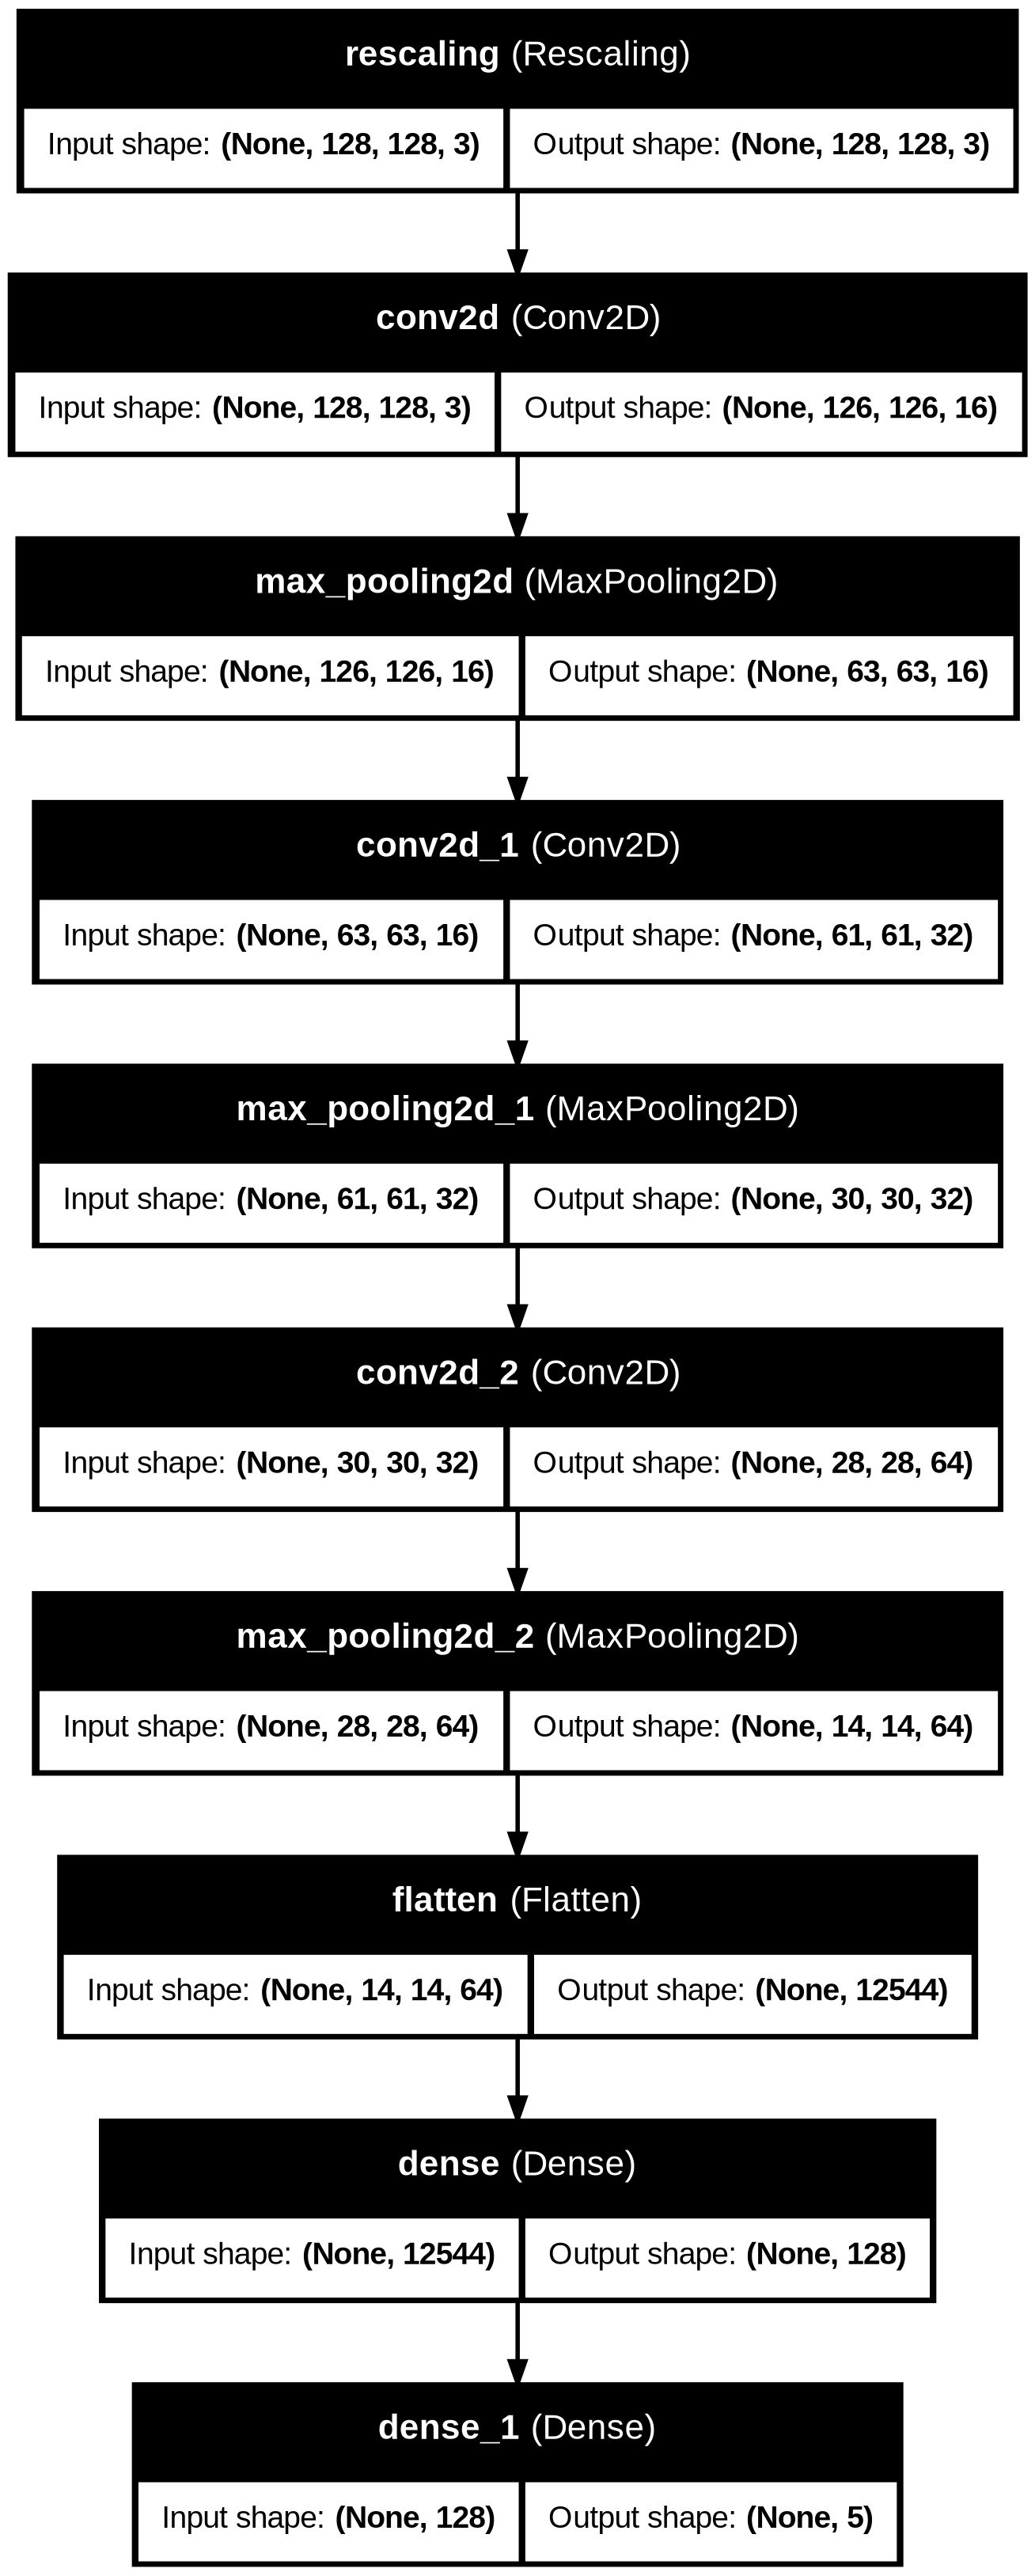

In [8]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    to_file='cnn_architecture.png',
    show_shapes=True,
    show_layer_names=True
)

In [9]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [10]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
318/318 ━━━━━━━━━━━━━━━━━━━━ 2027s 6s/step - accuracy: 0.5477 - loss: 1.1499 - val_accuracy: 0.6518 - val_loss: 0.9185
Epoch 2/5
318/318 ━━━━━━━━━━━━━━━━━━━━ 29s 93ms/step - accuracy: 0.6850 - loss: 0.8297 - val_accuracy: 0.6821 - val_loss: 0.8154
Epoch 3/5
318/318 ━━━━━━━━━━━━━━━━━━━━ 25s 78ms/step - accuracy: 0.7485 - loss: 0.6691 - val_accuracy: 0.7349 - val_loss: 0.7012
Epoch 4/5
318/318 ━━━━━━━━━━━━━━━━━━━━ 24s 74ms/step - accuracy: 0.7944 - loss: 0.5515 - val_accuracy: 0.7478 - val_loss: 0.6920
Epoch 5/5
318/318 ━━━━━━━━━━━━━━━━━━━━ 27s 83ms/step - accuracy: 0.8382 - loss: 0.4248 - val_accuracy: 0.7502 - val_loss: 0.7557


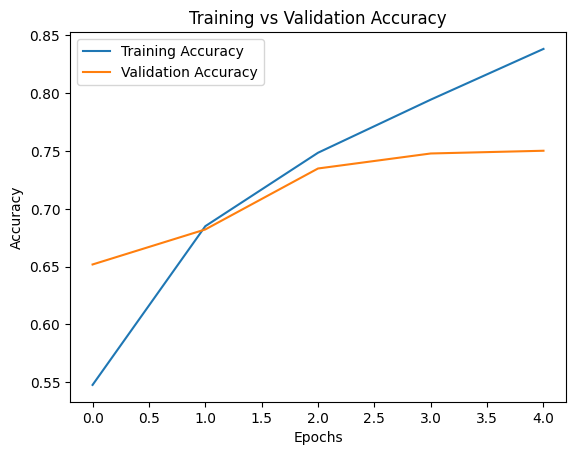

In [11]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

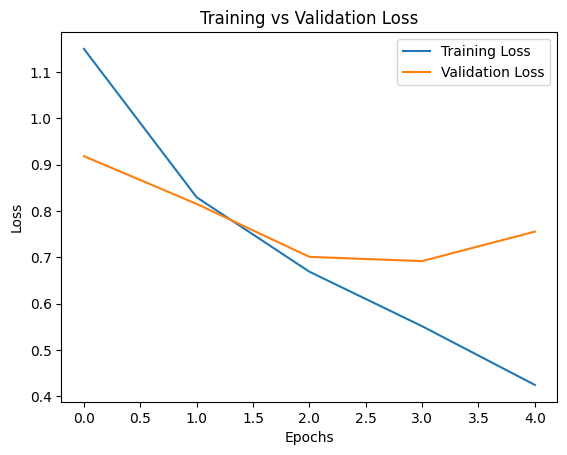

In [12]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step


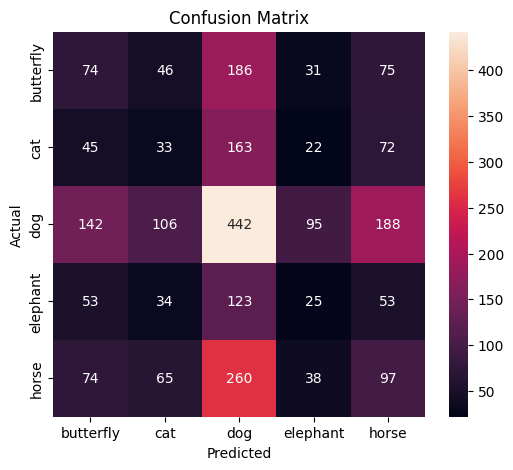

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

y_true = np.concatenate([y for x, y in val_data], axis=0)

y_pred = np.argmax(
    model.predict(val_data),
    axis=1
)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()

In [14]:
test_loss, test_accuracy = model.evaluate(val_data)

print("Test Accuracy:", test_accuracy * 100, "%")

accuracy_text = f"{test_accuracy * 100:.2f}%"

80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.7502 - loss: 0.7557
Test Accuracy: 75.01966953277588 %


In [15]:
model.save("/content/drive/MyDrive/animal_model.h5")

In [16]:
def predict_animal(img):

    img = img.resize((128,128))

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array)[0]

    idx = np.argmax(prediction)

    result = class_names[idx]

    confidence = prediction[idx] * 100

    return f"Prediction: {result} ({confidence:.2f}%)"

In [17]:
css_style = """
body {
    background: linear-gradient(to right, #74ebd5, #ACB6E5);
}

.gradio-container {
    border-radius: 20px;
    padding: 20px;
}
"""

In [18]:
interface = gr.Interface(
    fn=predict_animal,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="Animal Species Recognition",
    description="Upload an image and AI will predict the animal.",
    css=css_style
)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  super().__init__(


In [20]:
interface.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9daf8e68b7497195ef.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
